## Problema - Organización y búsqueda de productos en una tienda

# Algoritmo Creativo

## Andres Matias Carballo
## Juan Felipe Herrera
## Laura Juliana Ceron


## 1) Descripción del problema **[1 pts]**

Una tienda tiene muchos productos registrados y recorrer toda una lista cada vez que necesita consultar uno es poco eficiente. Para resolverlo, el programa organiza el inventario en una **Tabla Hash** de tamaño `m` (lo define el usuario). Cada producto se identifica con un **código numérico** (la llave) y se guarda en la posición que indica la función hash `h(código) = código % m`. Para buscar, eliminar o actualizar un producto solo se revisa esa posición, sin recorrer toda la tabla. Si dos productos caen en la misma posición (colisión), se guardan juntos en una lista (encadenamiento).

### Datos de entrada (lo que recibe el programa por teclado)

| Dato | Tipo | Valores permitidos | Para qué se usa |
| :--- | :--- | :--- | :--- |
| Opción del menú | entero | 1 a 7 | Elegir la operación: crear, insertar, buscar, eliminar, actualizar, mostrar o salir |
| Tamaño de la tabla `m` | entero | mayor o igual a 1 | Número de posiciones de la tabla (índices 0 a m-1) |
| Cantidad de productos `n` | entero | mayor o igual a 1 | Cuántos productos se registran en esa operación |
| Código del producto | entero | mayor o igual a 0, no repetido | Es la llave: define la posición con `código % m` |
| Nombre | texto | no vacío | Nombre del producto |
| Precio | entero, sin puntos ni comas | mayor o igual a 0 | Precio del producto en pesos |
| Cantidad disponible | entero | mayor o igual a 0 | Unidades que hay en el inventario |
| Código a buscar, eliminar o actualizar | entero | mayor o igual a 0 | Producto sobre el que se opera |
| Nueva cantidad | entero | mayor o igual a 0 | Reemplaza la cantidad disponible de un producto |

Si el usuario escribe texto, deja el campo vacío, escribe un negativo o un decimal, el programa muestra un error y vuelve a preguntar.

### Datos de salida (lo que muestra el programa)

| Operación | Salida |
| :--- | :--- |
| Crear la tabla | `Tabla creada con m posiciones.` y la tabla con las `m` posiciones en `Vacío` |
| Insertar | Por cada producto: `Producto <código> guardado en el índice <i>`, y antes `Colisión en el índice <i>` si esa posición ya tenía productos. Al final, la tabla completa |
| Mostrar la tabla | Una línea por posición: `<índice> -> Vacío` o `<índice> -> <código> - <nombre> ...` con todos los productos de esa posición |
| Buscar | Si existe: `Producto encontrado` con código, nombre, precio (`$`) y cantidad disponible. Si no: `El producto no está registrado.` |
| Eliminar | Si existe: `Producto eliminado correctamente.` y la tabla actualizada. Si no: `No se encontró el producto.` |
| Actualizar | Si existe: nombre y cantidad actual, luego `Inventario actualizado correctamente.` y `<nombre> - <nueva cantidad> unidades`. Si no: `No se encontró el producto.` |
| Código repetido | `Ya existe un producto con ese código.` y vuelve a pedir el código |
| Operar sin crear la tabla | `Primero debe crear la tabla (opción 1).` |

**Ejemplo:** con `m = 7` y el producto `101 - Arroz - 4500 - 20`, como `101 % 7 = 3`, el programa muestra `Producto 101 guardado en el índice 3` y en la tabla aparece `3 -> 101 - Arroz`.

## 2) Requerimientos **[2 pts]**

**Funcionales**

- **RF1.** El programa permite al usuario indicar el tamaño `m` de la tabla hash y crea `m` posiciones vacías.
- **RF2.** El programa permite registrar `n` productos, cada uno con código, nombre, precio y cantidad disponible.
- **RF3.** La posición de cada producto se calcula con la función hash `h(código) = código % m`.
- **RF4.** Las colisiones se resuelven mediante encadenamiento: una posición puede guardar varios productos.
- **RF5.** No se permiten dos productos con el mismo código.
- **RF6.** El programa permite buscar un producto por su código, calculando primero su posición con la función hash.
- **RF7.** El programa permite eliminar un producto por su código, sin afectar a los demás.
- **RF8.** El programa permite actualizar la cantidad disponible de un producto buscándolo con la tabla hash.
- **RF9.** El programa permite mostrar el contenido completo de la tabla, evidenciando las colisiones.

**No funcionales**

- **RNF1.** La tabla hash se implementa manualmente con listas de Python, sin usar diccionarios ni librerías para la estructura.
- **RNF2.** El código usa solo estructuras básicas (listas, `if`, `for`, `while` y funciones) para que sea fácil de entender y explicar.
- **RNF3.** La búsqueda y la eliminación no recorren toda la tabla: primero usan la función hash para ir a la posición correspondiente.
- **RNF4.** Toda entrada del usuario se valida (texto, vacío, negativos, decimales); el programa no se detiene por un error de digitación.
- **RNF5.** El código está organizado en funciones, cada una con una sola responsabilidad.
- **RNF6.** Los mensajes al usuario están en español y son claros.

## 3) Historias de usuario **[2 pts]**

**HU1. Crear la tabla.** *Como* encargado del inventario, *quiero* indicar el tamaño `m` de la tabla hash, *para* que el programa prepare las posiciones donde guardaré los productos.
- *Criterio de aceptación 1:* si escribo `m = 7`, se crean 7 posiciones (0 a 6) y todas se muestran como `Vacío`.
- *Criterio de aceptación 2:* si escribo `0`, una letra o dejo el campo vacío, el programa lo rechaza y vuelve a preguntar.

**HU2. Registrar productos.** *Como* encargado del inventario, *quiero* registrar productos con código, nombre, precio y cantidad, *para* tenerlos organizados en la tabla.
- *Criterio de aceptación 1:* con `m = 7`, el producto con código 101 queda en la posición 3 (`101 % 7 = 3`).
- *Criterio de aceptación 2:* si registro el 108 (que también da 3), el programa avisa la colisión y lo guarda en la misma posición, junto al 101.
- *Criterio de aceptación 3:* si escribo un código que ya existe, el programa no lo guarda y me pide otro.
- *Criterio de aceptación 4:* al terminar de registrar, se muestra la tabla completa.

**HU3. Buscar un producto.** *Como* vendedor, *quiero* consultar un producto por su código, *para* conocer su precio y cantidad sin revisar todo el inventario.
- *Criterio de aceptación 1:* si busco el 108, el programa muestra `Producto encontrado` con código 108, nombre Huevos, precio $16000 y cantidad 12.
- *Criterio de aceptación 2:* el programa solo revisa la posición calculada con la función hash, no toda la tabla.
- *Criterio de aceptación 3:* si busco un código que no existe, muestra `El producto no está registrado.`

**HU4. Eliminar un producto.** *Como* encargado del inventario, *quiero* eliminar un producto por su código, *para* sacar del inventario lo que ya no se vende.
- *Criterio de aceptación 1:* si en la posición 3 están el 101, el 108 y el 115 y elimino el 108, quedan solo el 101 y el 115.
- *Criterio de aceptación 2:* si el código no existe, muestra `No se encontró el producto.` y la tabla no cambia.

**HU5. Actualizar la cantidad.** *Como* encargado del inventario, *quiero* cambiar la cantidad disponible de un producto, *para* mantener el inventario al día.
- *Criterio de aceptación 1:* si el Arroz (código 101) tiene 20 unidades y escribo 35, el programa muestra `Inventario actualizado correctamente.` y `Arroz - 35 unidades`.
- *Criterio de aceptación 2:* el producto se busca usando la tabla hash.
- *Criterio de aceptación 3:* si el código no existe, muestra `No se encontró el producto.`

## 4) Diagramas de flujo **[5 pts]**

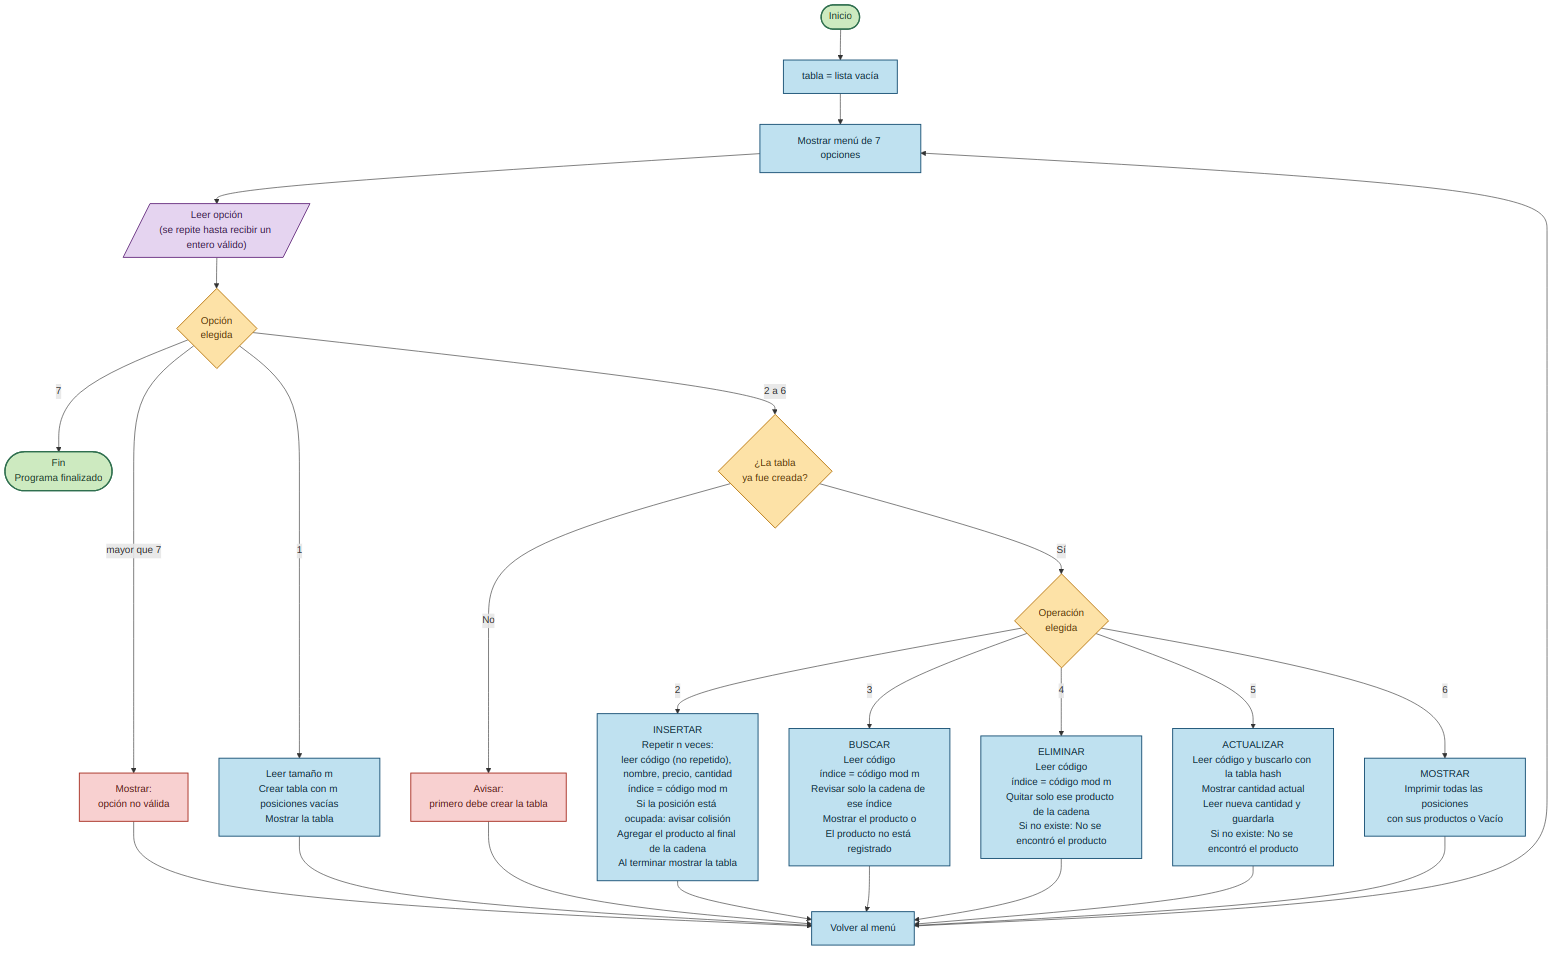

**Descripción del diagrama:** el programa empieza con la tabla vacía y entra en un ciclo: muestra el menú, lee la opción (se repite hasta recibir un entero válido) y decide qué hacer.

- Con la opción **7** el programa termina. Con un número mayor a 7 avisa que la opción no es válida.
- Con la opción **1** pide el tamaño `m`, crea la tabla con `m` posiciones vacías y la muestra.
- Con las opciones **2 a 6** primero comprueba que la tabla ya exista; si no, avisa que debe crearla.
- Con la tabla creada: la opción **2** inserta `n` productos (verifica que el código no esté repetido, calcula `índice = código mod m`, avisa la colisión si la posición está ocupada y agrega el producto al final de la cadena); la opción **3** busca revisando solo la cadena de ese índice; la opción **4** elimina solo ese producto; la opción **5** busca el producto con la tabla hash, muestra su cantidad actual y guarda la nueva; la opción **6** muestra toda la tabla.
- Al terminar cualquier operación, el programa vuelve al menú.

## 5) Diagramas de secuencia **[5 pts]**

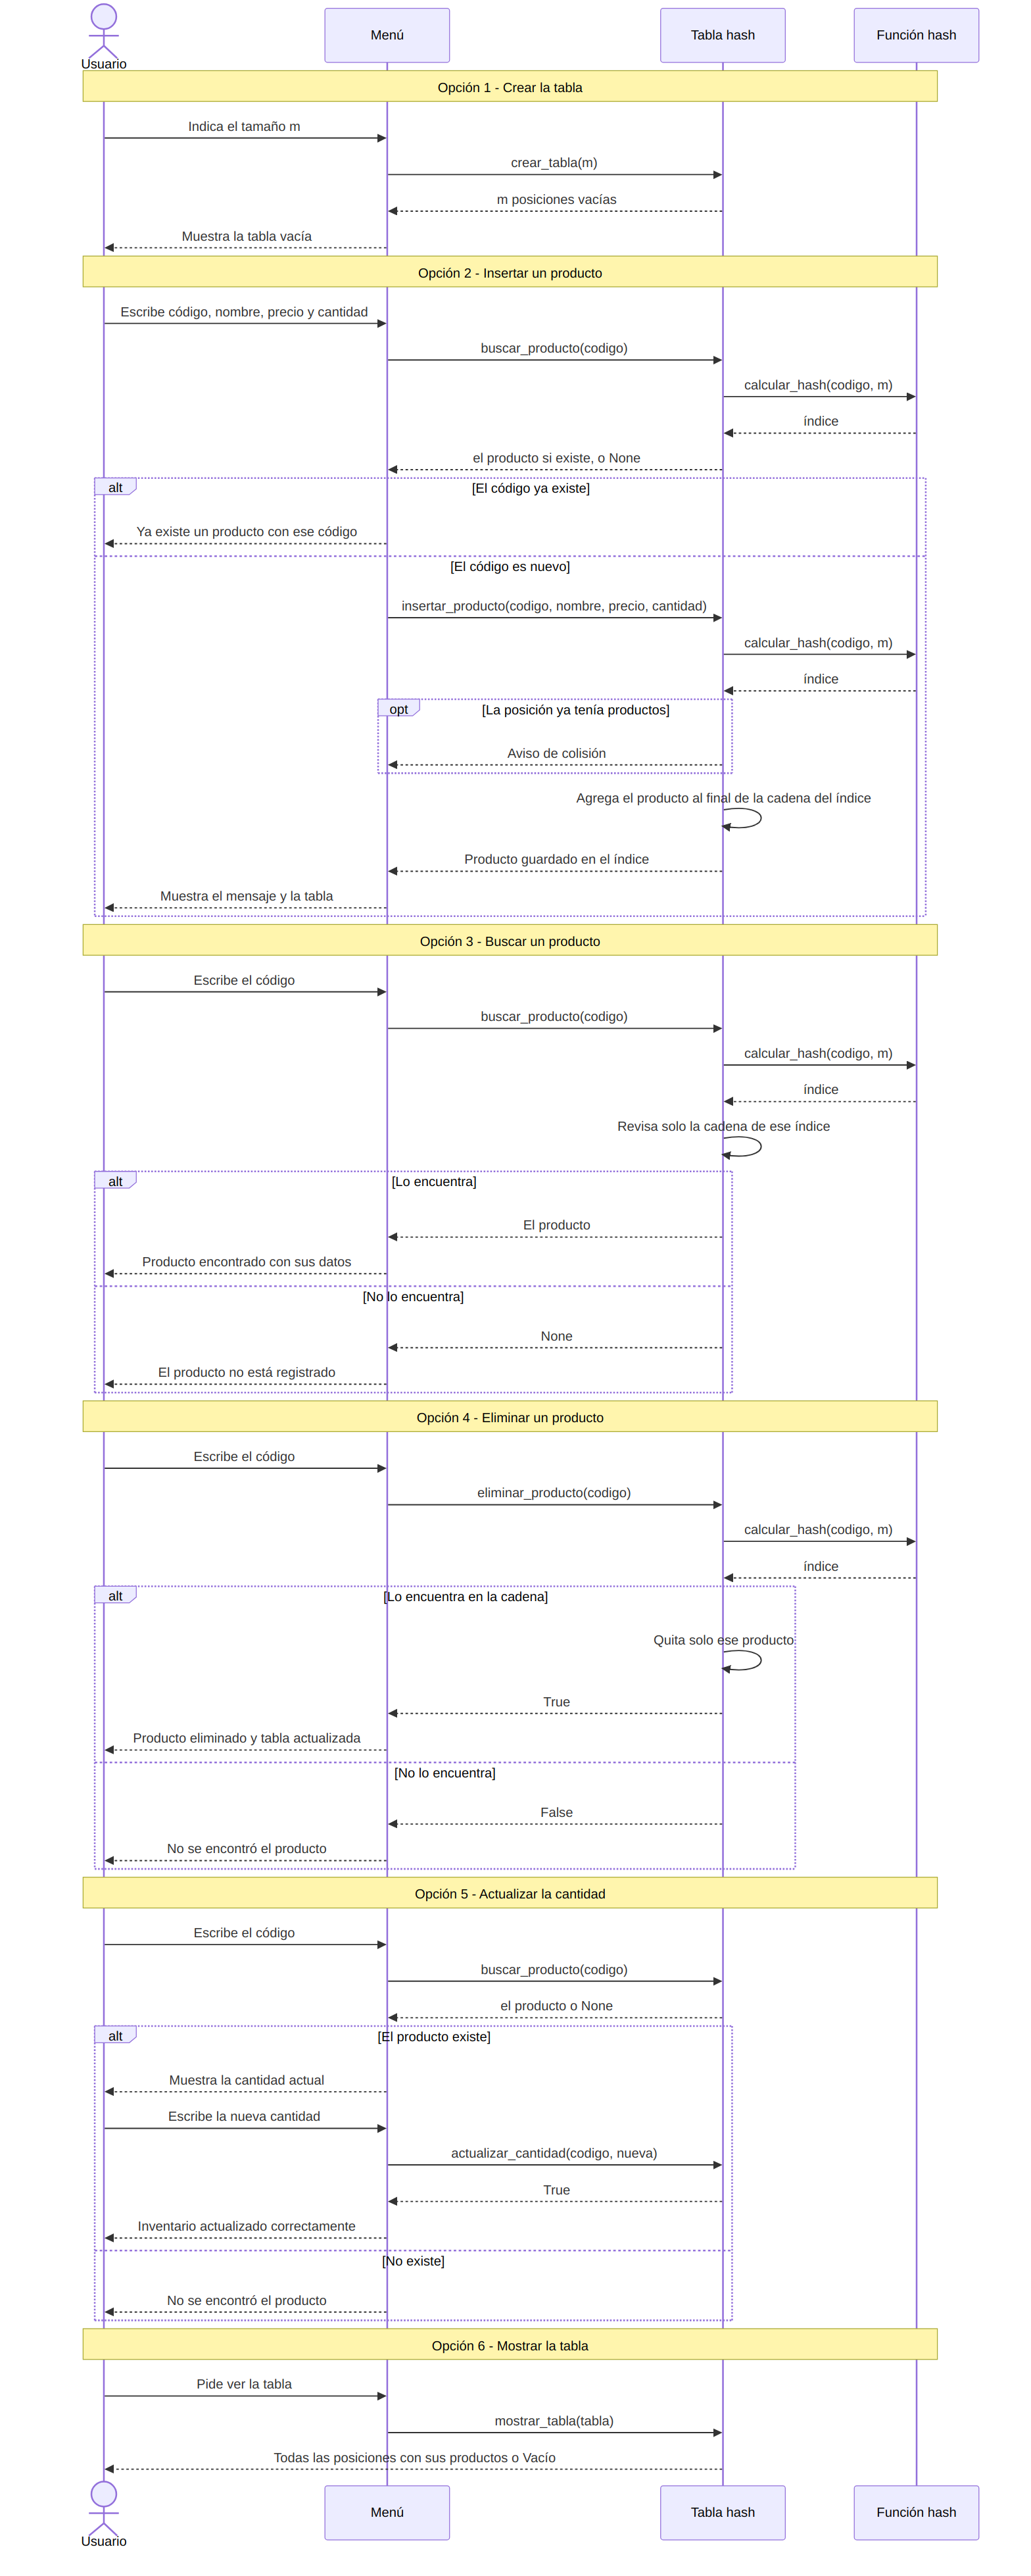

**Descripción del diagrama:** participan cuatro elementos: el **Usuario**, el **Menú** (la función `ejecutar_menu`, que pide los datos y muestra los mensajes), la **Tabla hash** (las funciones que guardan y consultan los productos) y la **Función hash** (`calcular_hash`, que dice en qué posición va cada código).

- **Crear la tabla:** el usuario indica `m`, el menú llama a `crear_tabla(m)` y muestra la tabla vacía.
- **Insertar:** el menú primero llama a `buscar_producto` para ver si el código ya existe. Si existe, avisa al usuario. Si es nuevo, llama a `insertar_producto`, que calcula el índice con la función hash, avisa si hay colisión y agrega el producto al final de la cadena de esa posición.
- **Buscar:** la tabla pide el índice a la función hash y revisa solo la cadena de ese índice. Devuelve el producto o `None`, y el menú muestra el resultado.
- **Eliminar:** la tabla calcula el índice y quita solo ese producto; responde `True` si lo eliminó o `False` si no estaba.
- **Actualizar:** el menú busca el producto; si existe, muestra la cantidad actual, recibe la nueva y llama a `actualizar_cantidad`.
- **Mostrar:** `mostrar_tabla` imprime todas las posiciones con sus productos o `Vacío`.

## 6) Diagramas de casos de uso **[5 pts]**

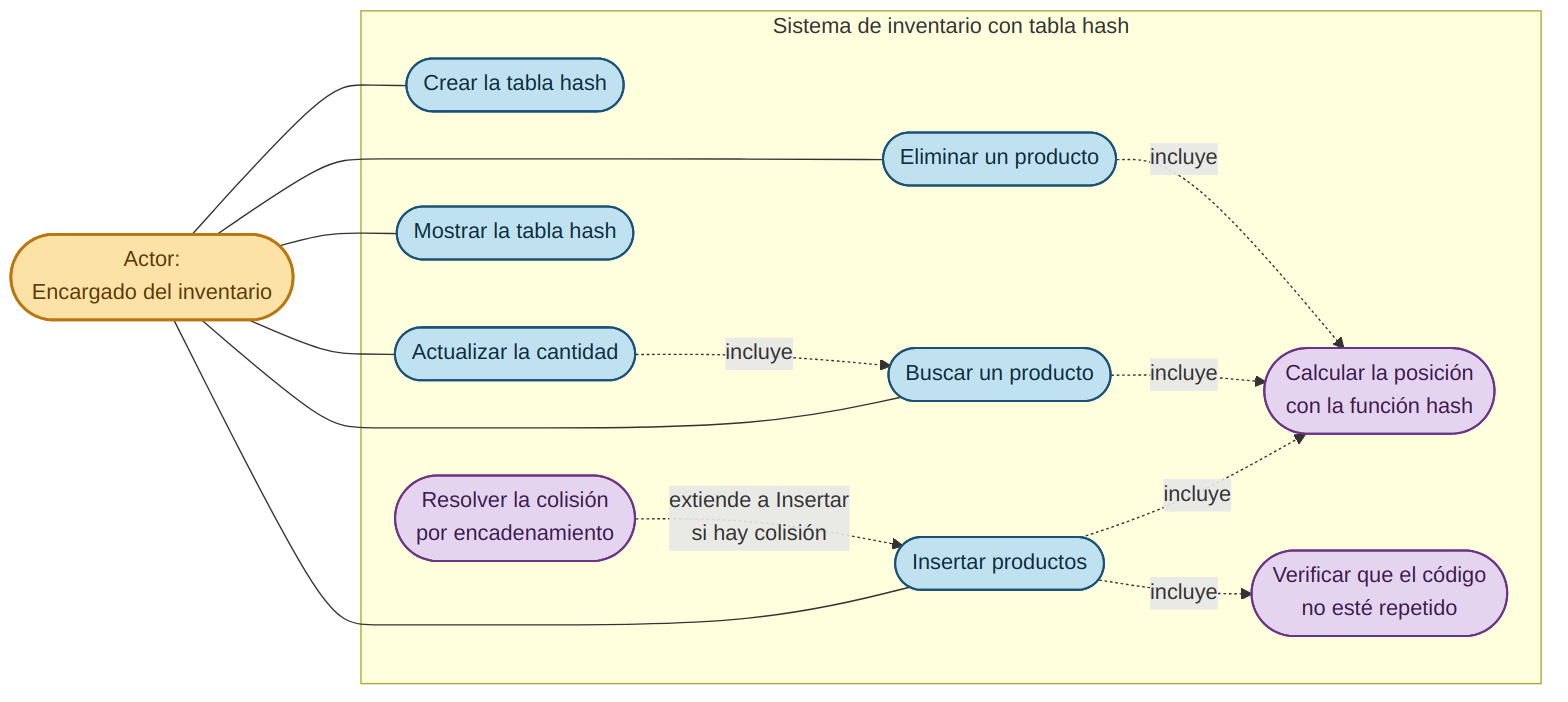

**Descripción del diagrama:** hay un solo actor, el **encargado del inventario**, que usa el sistema para seis casos de uso principales: crear la tabla hash, insertar productos, buscar un producto, eliminar un producto, actualizar la cantidad y mostrar la tabla hash.

Además hay tres casos de uso de apoyo (en morado), que el usuario no ejecuta directamente:

- **Calcular la posición con la función hash:** lo *incluyen* insertar, buscar y eliminar, porque todos necesitan saber en qué posición está o va el producto.
- **Verificar que el código no esté repetido:** lo *incluye* insertar, para cumplir la condición de que no haya dos productos con el mismo código.
- **Resolver la colisión por encadenamiento:** *extiende* a insertar, y solo ocurre cuando la posición calculada ya tiene productos.

Actualizar la cantidad *incluye* buscar un producto, porque primero debe encontrarlo con la tabla hash.

## 7) Análisis de complejidad **[5 pts]**

### Notación

- `n`: cantidad de productos guardados en la tabla.
- `m`: tamaño de la tabla (número de posiciones).
- `k`: cantidad de productos que hay que revisar dentro de una cadena (`0 <= k <= n`).

### Justificación

La función hash `código % m` es una sola operación, así que calcular la posición cuesta un tiempo constante. Buscar, insertar (por la verificación de código repetido), eliminar y actualizar siguen el mismo patrón: calculan la posición y recorren **solo la cadena de esa posición**, no toda la tabla. Por eso su costo no depende directamente de `n`, sino de `k`, la longitud de esa cadena:

- Si los productos quedan bien repartidos, cada cadena es corta (`k` pequeño) y la operación casi no depende de `n`.
- Si todos los productos caen en la misma posición (por ejemplo, con `m = 1`), la cadena tiene `n` productos y hay que recorrerlos todos.

`mostrar_tabla` visita las `m` posiciones y los `n` productos, y `crear_tabla` repite `m` veces un `append`; por eso ninguna de las dos depende de cómo estén repartidos los productos.

### Función T(n)

| Operación | T(n) | Qué representa |
| :--- | :--- | :--- |
| `calcular_hash` | `T = c` | Un solo residuo |
| `crear_tabla` | `T(m) = c * m` | El `for` repite `m` veces |
| `buscar_producto` | `T(n) = c1 + c2 * k` | Calcular la posición (`c1`) y comparar `k` productos (`c2` cada uno) |
| `insertar_producto` | `T(n) = c1 + c2 * k + c3` | Verificar repetido (recorre `k`) y agregar al final (`c3`) |
| `eliminar_producto` | `T(n) = c1 + c2 * k` | Calcular la posición, recorrer `k` y quitar el producto |
| `actualizar_cantidad` | `T(n) = c1 + c2 * k + c3` | Buscar y cambiar el valor (`c3`) |
| `mostrar_tabla` | `T(m, n) = c1 * m + c2 * n` | Visita `m` posiciones y `n` productos |
| Registrar `n` productos | `T(n) = (c1 + c3) * n + c2 * (k0 + k1 + ... + k(n-1))` | Suma de lo que cuesta cada inserción; `ki` es cuántos productos ya había en la cadena |

Las constantes `c1`, `c2`, `c3` representan el costo de pasos individuales (calcular el hash, comparar un código, agregar al final); no cambian el orden de crecimiento.

### Mejor y peor caso

| Operación | Mejor caso | Cuándo ocurre | Peor caso | Cuándo ocurre |
| :--- | :---: | :--- | :---: | :--- |
| `buscar_producto` | Ω(1) | La posición está vacía o el producto es el primero de su cadena | O(n) | Todos los productos están en la misma posición y el buscado es el último o no existe |
| `insertar_producto` | Ω(1) | La posición está vacía | O(n) | Todos están en la misma posición: para verificar el código repetido se revisan los `n` |
| `eliminar_producto` | Ω(1) | La posición está vacía o tiene un solo producto | O(n) | La cadena contiene los `n` productos |
| `actualizar_cantidad` | Ω(1) | Igual que buscar | O(n) | Igual que buscar |
| `mostrar_tabla` | Ω(m + n) | Siempre visita todo | O(m + n) | Siempre visita todo (no tiene mejor ni peor caso) |
| `crear_tabla` | Ω(m) | Siempre repite `m` veces | O(m) | Siempre repite `m` veces |
| Registrar `n` productos | Ω(n) | Cada producto cae en una posición vacía o de cadena corta | O(n²) | Todos en la misma posición: `0 + 1 + ... + (n-1) = n(n-1)/2` comparaciones |

### Gráfica

La gráfica de la izquierda compara, para una sola operación (buscar, insertar, eliminar o actualizar), el mejor caso `T(n) = 1` con el peor caso `T(n) = n`. La de la derecha compara el mejor y el peor caso de registrar `n` productos.

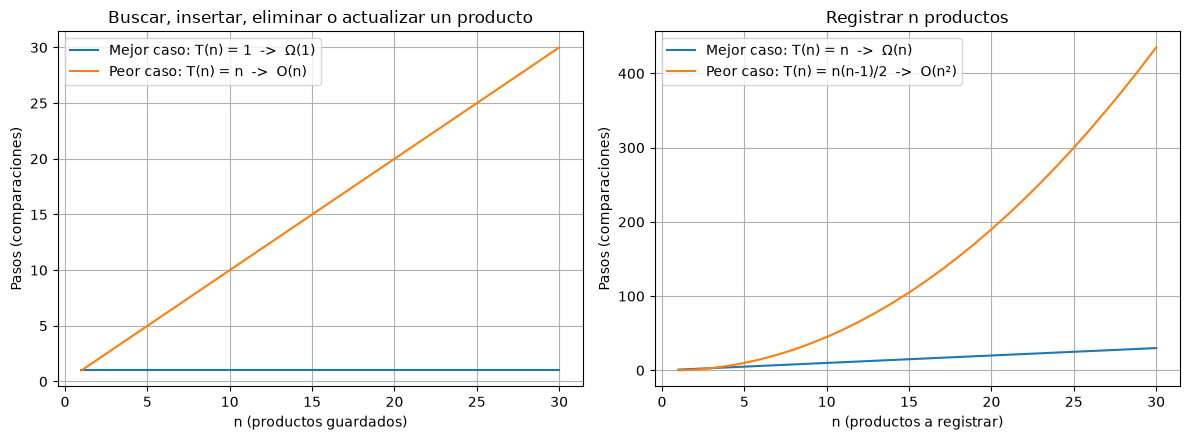

In [17]:
import matplotlib.pyplot as plt

n = list(range(1, 31))

mejor = []
peor = []
registrar_mejor = []
registrar_peor = []
for valor in n:
    mejor.append(1)
    peor.append(valor)
    registrar_mejor.append(valor)
    registrar_peor.append(valor * (valor - 1) / 2)

plt.figure(figsize=(12, 4.5))

plt.subplot(1, 2, 1)
plt.plot(n, mejor, label="Mejor caso: T(n) = 1  ->  Ω(1)")
plt.plot(n, peor, label="Peor caso: T(n) = n  ->  O(n)")
plt.title("Buscar, insertar, eliminar o actualizar un producto")
plt.xlabel("n (productos guardados)")
plt.ylabel("Pasos (comparaciones)")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(n, registrar_mejor, label="Mejor caso: T(n) = n  ->  Ω(n)")
plt.plot(n, registrar_peor, label="Peor caso: T(n) = n(n-1)/2  ->  O(n²)")
plt.title("Registrar n productos")
plt.xlabel("n (productos a registrar)")
plt.ylabel("Pasos (comparaciones)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## 8) Código funcional **[10 pts]**

El código está organizado en funciones. La tabla hash es una **lista de listas**: cada posición es una lista (la cadena) que guarda los productos que caen allí, y cada producto es una lista `[código, nombre, precio, cantidad]`.

| Función | Qué hace |
| :--- | :--- |
| `crear_tabla(m)` | Crea `m` posiciones vacías |
| `calcular_hash(codigo, m)` | Devuelve la posición: `codigo % m` |
| `buscar_producto(tabla, codigo)` | Busca un producto revisando solo la cadena de su posición |
| `insertar_producto(...)` | Guarda un producto (rechaza códigos repetidos y avisa las colisiones) |
| `eliminar_producto(tabla, codigo)` | Elimina solo ese producto |
| `actualizar_cantidad(...)` | Cambia la cantidad disponible |
| `mostrar_producto(producto)` / `mostrar_tabla(tabla)` | Imprimen un producto / toda la tabla |
| `leer_entero` / `leer_texto` | Piden datos al usuario y repiten la pregunta si la entrada no es válida |
| `ejecutar_menu()` | Menú interactivo que une todas las funciones (se ejecuta en el **Anexo** al final del notebook) |

In [18]:
def crear_tabla(m):
    tabla = []
    for i in range(m):
        tabla.append([])
    return tabla


def calcular_hash(codigo, m):
    return codigo % m


def buscar_producto(tabla, codigo):
    indice = calcular_hash(codigo, len(tabla))
    for producto in tabla[indice]:
        if producto[0] == codigo:
            return producto
    return None


def insertar_producto(tabla, codigo, nombre, precio, cantidad):
    if buscar_producto(tabla, codigo) is not None:
        return False

    indice = calcular_hash(codigo, len(tabla))
    if len(tabla[indice]) > 0:
        print("Colisión en el índice", indice, "-> el producto se agrega a la cadena")
    tabla[indice].append([codigo, nombre, precio, cantidad])
    print("Producto", codigo, "guardado en el índice", indice)
    return True


def eliminar_producto(tabla, codigo):
    indice = calcular_hash(codigo, len(tabla))
    cadena = tabla[indice]
    for i in range(len(cadena)):
        if cadena[i][0] == codigo:
            cadena.pop(i)
            return True
    return False


def actualizar_cantidad(tabla, codigo, nueva_cantidad):
    producto = buscar_producto(tabla, codigo)
    if producto is None:
        return False
    producto[3] = nueva_cantidad
    return True


def mostrar_producto(producto):
    print("Producto encontrado")
    print("Código:", producto[0])
    print("Nombre:", producto[1])
    print("Precio: $" + str(producto[2]))
    print("Cantidad disponible:", producto[3])


def mostrar_tabla(tabla):
    print("========================================")
    print("              TABLA HASH")
    print("========================================")
    for i in range(len(tabla)):
        if len(tabla[i]) == 0:
            print(i, "-> Vacío")
        else:
            texto = ""
            for producto in tabla[i]:
                texto = texto + str(producto[0]) + " - " + producto[1] + "     "
            print(i, "->", texto)
    print("========================================")


def leer_entero(mensaje, minimo):
    texto = input(mensaje).strip()
    while not texto.isdigit() or int(texto) < minimo:
        print("Entrada no válida. Escriba un número entero (sin puntos ni comas) mayor o igual a", minimo)
        texto = input(mensaje).strip()
    return int(texto)


def leer_texto(mensaje):
    texto = input(mensaje).strip()
    while texto == "":
        print("El campo no puede estar vacío.")
        texto = input(mensaje).strip()
    return texto


def ejecutar_menu():
    tabla = []
    opcion = 0

    while opcion != 7:
        print()
        print("===== INVENTARIO CON TABLA HASH =====")
        print("1. Crear la tabla hash")
        print("2. Insertar productos")
        print("3. Buscar un producto")
        print("4. Eliminar un producto")
        print("5. Actualizar cantidad de un producto")
        print("6. Mostrar la tabla hash")
        print("7. Salir")
        opcion = leer_entero("Seleccione una opción: ", 1)

        if opcion == 1:
            m = leer_entero("Ingrese el tamaño de la tabla hash: ", 1)
            tabla = crear_tabla(m)
            print("Tabla creada con", m, "posiciones.")
            mostrar_tabla(tabla)

        elif opcion >= 2 and opcion <= 6 and len(tabla) == 0:
            print("Primero debe crear la tabla (opción 1).")

        elif opcion == 2:
            n = leer_entero("¿Cuántos productos desea registrar?: ", 1)
            for i in range(n):
                print("Producto", i + 1)
                codigo = leer_entero("Código: ", 0)
                while buscar_producto(tabla, codigo) is not None:
                    print("Ya existe un producto con ese código.")
                    codigo = leer_entero("Código: ", 0)
                nombre = leer_texto("Nombre: ")
                precio = leer_entero("Precio: ", 0)
                cantidad = leer_entero("Cantidad: ", 0)
                insertar_producto(tabla, codigo, nombre, precio, cantidad)
            mostrar_tabla(tabla)

        elif opcion == 3:
            codigo = leer_entero("Ingrese el código del producto: ", 0)
            producto = buscar_producto(tabla, codigo)
            if producto is None:
                print("El producto no está registrado.")
            else:
                mostrar_producto(producto)

        elif opcion == 4:
            codigo = leer_entero("Código del producto que desea eliminar: ", 0)
            if eliminar_producto(tabla, codigo):
                print("Producto eliminado correctamente.")
                mostrar_tabla(tabla)
            else:
                print("No se encontró el producto.")

        elif opcion == 5:
            codigo = leer_entero("Código: ", 0)
            producto = buscar_producto(tabla, codigo)
            if producto is None:
                print("No se encontró el producto.")
            else:
                print("Producto:", producto[1])
                print("Cantidad actual:", producto[3])
                nueva = leer_entero("Nueva cantidad: ", 0)
                actualizar_cantidad(tabla, codigo, nueva)
                print("Inventario actualizado correctamente.")
                print(producto[1], "-", nueva, "unidades")

        elif opcion == 6:
            mostrar_tabla(tabla)

        elif opcion == 7:
            print("Programa finalizado.")

        else:
            print("Opción no válida. Elija un número entre 1 y 7.")

ejecutar_menu()


===== INVENTARIO CON TABLA HASH =====
1. Crear la tabla hash
2. Insertar productos
3. Buscar un producto
4. Eliminar un producto
5. Actualizar cantidad de un producto
6. Mostrar la tabla hash
7. Salir
Tabla creada con 7 posiciones.
              TABLA HASH
0 -> Vacío
1 -> Vacío
2 -> Vacío
3 -> Vacío
4 -> Vacío
5 -> Vacío
6 -> Vacío

===== INVENTARIO CON TABLA HASH =====
1. Crear la tabla hash
2. Insertar productos
3. Buscar un producto
4. Eliminar un producto
5. Actualizar cantidad de un producto
6. Mostrar la tabla hash
7. Salir
Producto 1
Producto 101 guardado en el índice 3
Producto 2
Colisión en el índice 3 -> el producto se agrega a la cadena
Producto 108 guardado en el índice 3
Producto 3
Colisión en el índice 3 -> el producto se agrega a la cadena
Producto 115 guardado en el índice 3
Producto 4
Producto 312 guardado en el índice 4
Producto 5
Producto 302 guardado en el índice 1
Producto 6
Producto 209 guardado en el índice 6
              TABLA HASH
0 -> Vacío
1 -> 302 - Gallet

### Demostración de la ejecución

Esta celda usa las funciones anteriores con datos de ejemplo (`m = 7`) y no pide nada por teclado. Muestra la creación de la tabla, la inserción, las colisiones, una búsqueda exitosa, una búsqueda de un producto inexistente, la eliminación, la actualización del inventario y el estado final de la tabla.

In [19]:
print("1) CREACIÓN DE LA TABLA HASH (m = 7)")
tabla = crear_tabla(7)
mostrar_tabla(tabla)

print("\n2) INSERCIÓN DE PRODUCTOS (101, 108 y 115 colisionan en el índice 3)")
insertar_producto(tabla, 101, "Arroz", 4500, 20)
insertar_producto(tabla, 108, "Huevos", 16000, 12)
insertar_producto(tabla, 115, "Azúcar", 5000, 25)
insertar_producto(tabla, 312, "Café", 12000, 10)
insertar_producto(tabla, 302, "Galletas", 3000, 18)
insertar_producto(tabla, 209, "Leche", 3800, 15)
print()
mostrar_tabla(tabla)

print("\n3) INTENTO DE INSERTAR UN CÓDIGO REPETIDO (101)")
if insertar_producto(tabla, 101, "Arroz", 4500, 20) == False:
    print("No se insertó: ya existe un producto con el código 101.")

print("\n4) BÚSQUEDA EXITOSA (código 108)")
producto = buscar_producto(tabla, 108)
if producto is None:
    print("El producto no está registrado.")
else:
    mostrar_producto(producto)

print("\n5) BÚSQUEDA DE UN PRODUCTO INEXISTENTE (código 999)")
producto = buscar_producto(tabla, 999)
if producto is None:
    print("El producto no está registrado.")
else:
    mostrar_producto(producto)

print("\n6) ELIMINACIÓN DEL PRODUCTO 108")
if eliminar_producto(tabla, 108):
    print("Producto eliminado correctamente.")
else:
    print("No se encontró el producto.")
print("Eliminar un código que no existe (777):")
if eliminar_producto(tabla, 777):
    print("Producto eliminado correctamente.")
else:
    print("No se encontró el producto.")

print("\n7) ACTUALIZACIÓN DEL INVENTARIO (código 101)")
producto = buscar_producto(tabla, 101)
print("Producto:", producto[1])
print("Cantidad actual:", producto[3])
actualizar_cantidad(tabla, 101, 35)
print("Inventario actualizado correctamente.")
print(producto[1], "-", producto[3], "unidades")

print("\n8) ESTADO FINAL DE LA TABLA HASH")
mostrar_tabla(tabla)

1) CREACIÓN DE LA TABLA HASH (m = 7)
              TABLA HASH
0 -> Vacío
1 -> Vacío
2 -> Vacío
3 -> Vacío
4 -> Vacío
5 -> Vacío
6 -> Vacío

2) INSERCIÓN DE PRODUCTOS (101, 108 y 115 colisionan en el índice 3)
Producto 101 guardado en el índice 3
Colisión en el índice 3 -> el producto se agrega a la cadena
Producto 108 guardado en el índice 3
Colisión en el índice 3 -> el producto se agrega a la cadena
Producto 115 guardado en el índice 3
Producto 312 guardado en el índice 4
Producto 302 guardado en el índice 1
Producto 209 guardado en el índice 6

              TABLA HASH
0 -> Vacío
1 -> 302 - Galletas     
2 -> Vacío
3 -> 101 - Arroz     108 - Huevos     115 - Azúcar     
4 -> 312 - Café     
5 -> Vacío
6 -> 209 - Leche     

3) INTENTO DE INSERTAR UN CÓDIGO REPETIDO (101)
No se insertó: ya existe un producto con el código 101.

4) BÚSQUEDA EXITOSA (código 108)
Producto encontrado
Código: 108
Nombre: Huevos
Precio: $16000
Cantidad disponible: 12

5) BÚSQUEDA DE UN PRODUCTO INEXISTENTE

## 9) pruebas **[15 pts]**

La función `test` compara la salida obtenida con la esperada y muestra, para cada caso, la entrada usada, la salida esperada y la salida obtenida. Si algún caso falla, el notebook se detiene con un mensaje claro.

In [20]:
import io
from contextlib import redirect_stdout


def test(caso, entrada, got_output, expected_output):
    assert got_output == expected_output, f"Fallo en '{caso}': se obtuvo {got_output}, pero se esperaba {expected_output}"
    print(f"Paso caso de prueba: {caso}")
    print("   Entrada usada:", entrada)
    print("   Salida esperada:", expected_output)
    print("   Salida obtenida:", got_output)


def estado_tabla(tabla):
    # Deja solo los códigos de cada posición, para comparar la tabla fácilmente
    estado = []
    for cadena in tabla:
        codigos = []
        for producto in cadena:
            codigos.append(producto[0])
        estado.append(codigos)
    return estado


def armar_tabla(m, productos):
    # Crea una tabla y la llena sin imprimir los mensajes de insertar_producto
    tabla = crear_tabla(m)
    with redirect_stdout(io.StringIO()):
        for p in productos:
            insertar_producto(tabla, p[0], p[1], p[2], p[3])
    return tabla

## Pruebas de enunciado

Casos tomados directamente del enunciado del ejercicio: tabla de tamaño `m = 7`, los productos de ejemplo (101 Arroz, 108 Huevos, 115 Azúcar, 312 Café, 302 Galletas y 209 Leche), la colisión en la posición 3, la búsqueda exitosa del 108, la búsqueda de un producto inexistente, la eliminación del 108, la actualización del Arroz a 35 unidades, el rechazo de códigos repetidos y el formato de la tabla del Punto 7.

In [21]:
arroz = [101, "Arroz", 4500, 20]
huevos = [108, "Huevos", 16000, 12]
azucar = [115, "Azúcar", 5000, 25]
cafe = [312, "Café", 12000, 10]
galletas = [302, "Galletas", 3000, 18]
leche = [209, "Leche", 3800, 15]

test("Función hash: 101 % 7", "código = 101, m = 7", calcular_hash(101, 7), 3)
test("Función hash: 108 % 7 (colisiona con el 101)", "código = 108, m = 7", calcular_hash(108, 7), 3)

tabla = crear_tabla(7)
test("Tabla vacía de tamaño 7", "m = 7", estado_tabla(tabla), [[], [], [], [], [], [], []])

print("\n--- Se inserta el 101 (el programa imprime el mensaje de inserción) ---")
insertar_producto(tabla, 101, "Arroz", 4500, 20)
test("Insertar el 101 con m = 7 lo guarda en la posición 3", "101, Arroz, 4500, 20",
     estado_tabla(tabla), [[], [], [], [101], [], [], []])

print("\n--- Se insertan el 108 y el 115 (colisiones en la posición 3) ---")
insertar_producto(tabla, 108, "Huevos", 16000, 12)
insertar_producto(tabla, 115, "Azúcar", 5000, 25)
test("Colisión: 101, 108 y 115 quedan encadenados en la posición 3", "101, 108 y 115 con m = 7",
     estado_tabla(tabla), [[], [], [], [101, 108, 115], [], [], []])

print()
test("Búsqueda exitosa del 108", "código = 108", buscar_producto(tabla, 108), [108, "Huevos", 16000, 12])
test("Búsqueda de un producto inexistente", "código = 999", buscar_producto(tabla, 999), None)

test("Eliminar el 108 devuelve True", "código = 108", eliminar_producto(tabla, 108), True)
test("Después de eliminar el 108 quedan el 101 y el 115", "tabla después de eliminar el 108",
     estado_tabla(tabla), [[], [], [], [101, 115], [], [], []])
test("Eliminar un código que no existe", "código = 999", eliminar_producto(tabla, 999), False)

test("Actualizar la cantidad del 101 devuelve True", "código = 101, nueva cantidad = 35",
     actualizar_cantidad(tabla, 101, 35), True)
test("El Arroz queda con 35 unidades", "código = 101", buscar_producto(tabla, 101)[3], 35)

test("No se permite repetir un código", "insertar otra vez el 101",
     insertar_producto(tabla, 101, "Arroz", 4500, 20), False)
test("La tabla no cambia al rechazar el código repetido", "tabla después del intento",
     estado_tabla(tabla), [[], [], [], [101, 115], [], [], []])

tabla_completa = armar_tabla(7, [arroz, huevos, azucar, cafe, galletas, leche])
with redirect_stdout(io.StringIO()) as buffer:
    mostrar_tabla(tabla_completa)
filas = []
for linea in buffer.getvalue().splitlines()[3:10]:
    filas.append(" ".join(linea.split()))
esperado = ["0 -> Vacío", "1 -> 302 - Galletas", "2 -> Vacío", "3 -> 101 - Arroz 108 - Huevos 115 - Azúcar",
            "4 -> 312 - Café", "5 -> Vacío", "6 -> 209 - Leche"]
test("Mostrar la tabla (ejemplo del Punto 7 del enunciado)", "m = 7 con 101, 108, 115, 312, 302 y 209",
     filas, esperado)

print("\nTodas las pruebas de enunciado pasaron.")

Paso caso de prueba: Función hash: 101 % 7
   Entrada usada: código = 101, m = 7
   Salida esperada: 3
   Salida obtenida: 3
Paso caso de prueba: Función hash: 108 % 7 (colisiona con el 101)
   Entrada usada: código = 108, m = 7
   Salida esperada: 3
   Salida obtenida: 3
Paso caso de prueba: Tabla vacía de tamaño 7
   Entrada usada: m = 7
   Salida esperada: [[], [], [], [], [], [], []]
   Salida obtenida: [[], [], [], [], [], [], []]

--- Se inserta el 101 (el programa imprime el mensaje de inserción) ---
Producto 101 guardado en el índice 3
Paso caso de prueba: Insertar el 101 con m = 7 lo guarda en la posición 3
   Entrada usada: 101, Arroz, 4500, 20
   Salida esperada: [[], [], [], [101], [], [], []]
   Salida obtenida: [[], [], [], [101], [], [], []]

--- Se insertan el 108 y el 115 (colisiones en la posición 3) ---
Colisión en el índice 3 -> el producto se agrega a la cadena
Producto 108 guardado en el índice 3
Colisión en el índice 3 -> el producto se agrega a la cadena
Product

## Pruebas propias

Casos creados por nosotros para revisar situaciones que el enunciado no muestra: tabla de tamaño 1, otros tamaños de tabla, el código 0, que la posición siempre quede entre 0 y `m-1`, eliminar el primero, el último o el único producto de una cadena, eliminar dos veces el mismo código, actualizar un producto inexistente, actualizar la cantidad a 0 y productos con el mismo nombre pero código distinto.

Casos tomados de UDebug: no aplica, porque este ejercicio es propio de la materia y no está publicado en esa página.

In [22]:
producto_a = [5, "A", 100, 1]
producto_b = [10, "B", 100, 1]
producto_c = [15, "C", 100, 1]

tabla = crear_tabla(7)
test("crear_tabla crea m posiciones", "m = 7", len(tabla), 7)
tabla[0].append("prueba")
test("Cada posición es una lista independiente", "se agrega algo solo a la posición 0", len(tabla[1]), 0)

test("Con m = 1 todos los productos van a la posición 0", "códigos 5, 10 y 15 con m = 1",
     estado_tabla(armar_tabla(1, [producto_a, producto_b, producto_c])), [[5, 10, 15]])

test("Con m = 5 no hay colisiones", "101, 108, 115 y 312 con m = 5",
     estado_tabla(armar_tabla(5, [[101, "Arroz", 4500, 20], [108, "Huevos", 16000, 12],
                                  [115, "Azúcar", 5000, 25], [312, "Café", 12000, 10]])),
     [[115], [101], [312], [108], []])

test("Con m = 4 el 108 y el 312 colisionan en la posición 0", "101, 108, 115 y 312 con m = 4",
     estado_tabla(armar_tabla(4, [[101, "Arroz", 4500, 20], [108, "Huevos", 16000, 12],
                                  [115, "Azúcar", 5000, 25], [312, "Café", 12000, 10]])),
     [[108, 312], [101], [], [115]])

test("El código 0 va a la posición 0", "código = 0, m = 7", calcular_hash(0, 7), 0)

todos_en_rango = True
for codigo in range(0, 100):
    posicion = calcular_hash(codigo, 7)
    if posicion < 0 or posicion > 6:
        todos_en_rango = False
test("La posición siempre está entre 0 y m-1", "códigos de 0 a 99 con m = 7", todos_en_rango, True)

tres = [[101, "Arroz", 4500, 20], [108, "Huevos", 16000, 12], [115, "Azúcar", 5000, 25]]

tabla = armar_tabla(7, tres)
test("Buscar un producto que está al final de la cadena (115)", "código = 115",
     buscar_producto(tabla, 115), [115, "Azúcar", 5000, 25])
test("Buscar un código inexistente que cae en una posición con productos", "código = 500 (500 % 7 = 3)",
     buscar_producto(tabla, 500), None)

tabla = armar_tabla(7, tres)
eliminar_producto(tabla, 101)
test("Eliminar el primero de una cadena", "eliminar el 101 de [101, 108, 115]", estado_tabla(tabla)[3], [108, 115])

tabla = armar_tabla(7, tres)
eliminar_producto(tabla, 115)
test("Eliminar el último de una cadena", "eliminar el 115 de [101, 108, 115]", estado_tabla(tabla)[3], [101, 108])

tabla = armar_tabla(7, [[312, "Café", 12000, 10]])
eliminar_producto(tabla, 312)
test("Eliminar el único producto deja la posición vacía", "eliminar el 312", estado_tabla(tabla)[4], [])

tabla = armar_tabla(7, tres)
eliminar_producto(tabla, 108)
test("Eliminar dos veces el mismo código", "eliminar el 108 por segunda vez", eliminar_producto(tabla, 108), False)

tabla = armar_tabla(7, tres)
test("Actualizar un producto que no existe", "código = 999, nueva cantidad = 5", actualizar_cantidad(tabla, 999, 5), False)
test("La cantidad se puede actualizar a 0", "código = 101, nueva cantidad = 0", actualizar_cantidad(tabla, 101, 0), True)
test("La cantidad quedó en 0", "código = 101", buscar_producto(tabla, 101)[3], 0)

tabla = crear_tabla(7)
with redirect_stdout(io.StringIO()):
    primero = insertar_producto(tabla, 7, "Arroz", 4500, 20)
    segundo = insertar_producto(tabla, 14, "Arroz", 4800, 10)
test("Dos productos con el mismo nombre pero código distinto sí se permiten", "7 - Arroz y 14 - Arroz",
     [primero, segundo, estado_tabla(tabla)[0]], [True, True, [7, 14]])

print("\nTodas las pruebas propias pasaron.")

Paso caso de prueba: crear_tabla crea m posiciones
   Entrada usada: m = 7
   Salida esperada: 7
   Salida obtenida: 7
Paso caso de prueba: Cada posición es una lista independiente
   Entrada usada: se agrega algo solo a la posición 0
   Salida esperada: 0
   Salida obtenida: 0
Paso caso de prueba: Con m = 1 todos los productos van a la posición 0
   Entrada usada: códigos 5, 10 y 15 con m = 1
   Salida esperada: [[5, 10, 15]]
   Salida obtenida: [[5, 10, 15]]
Paso caso de prueba: Con m = 5 no hay colisiones
   Entrada usada: 101, 108, 115 y 312 con m = 5
   Salida esperada: [[115], [101], [312], [108], []]
   Salida obtenida: [[115], [101], [312], [108], []]
Paso caso de prueba: Con m = 4 el 108 y el 312 colisionan en la posición 0
   Entrada usada: 101, 108, 115 y 312 con m = 4
   Salida esperada: [[108, 312], [101], [], [115]]
   Salida obtenida: [[108, 312], [101], [], [115]]
Paso caso de prueba: El código 0 va a la posición 0
   Entrada usada: código = 0, m = 7
   Salida esperada:

## Pruebas de Desempeño

Se mide el tiempo de **buscar un producto** (la operación principal de la tabla hash) con diferentes cantidades de productos, en dos situaciones:

- **Peor caso:** `m = 1`. Todos los productos caen en la misma posición, así que la cadena tiene `n` productos y se busca el último.
- **Mejor caso:** `m = n`. Cada producto queda en su propia posición, así que la cadena tiene un solo producto.

Para que la medición sea más estable, cada tiempo se mide 5 veces y se conserva el más rápido.

#### Código base para benchmarking

Generando datos .......................
Generando datos .......................


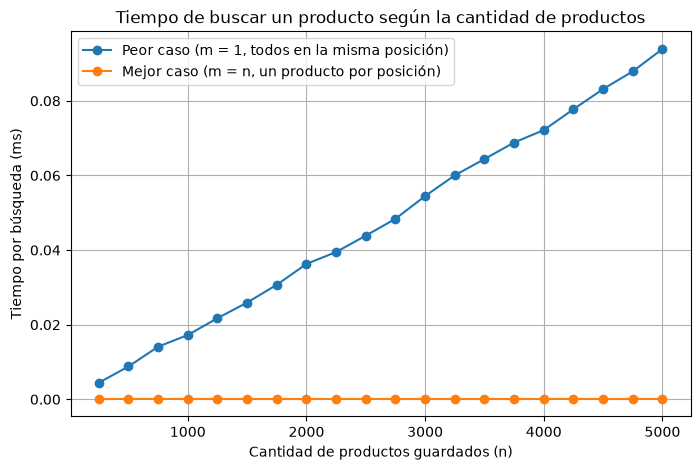

Peor caso:  con 250 productos = 0.00445 ms | con 5000 productos = 0.09389 ms
Mejor caso: con 250 productos = 9e-05 ms | con 5000 productos = 9e-05 ms


In [23]:
# Calcula el tiempo de ejecucion con base a diferentes tamaños de la entrada
# y nos da una lista de resultados, cada resultado contiene el tamaño de la entrada
# y el tiempo de ejecucion
# Se mide el tiempo de BUSCAR un producto en una tabla con "size" productos.
# peor_caso=True  -> m = 1: todos los productos caen en la misma posición
# peor_caso=False -> m = size: cada producto queda en su propia posición


def bench(n: int, step: int = 1, peor_caso: bool = True) -> list[tuple[int, float]]:
    print("Generando datos ...", end='')
    import time
    results: list[tuple[int, float]] = []

    for size in range(step, n, step):
        if peor_caso:
            m = 1
        else:
            m = size

        tabla = crear_tabla(m)
        for codigo in range(size):
            tabla[calcular_hash(codigo, m)].append([codigo, "Producto", 1000, 1])

        buscado = size - 1
        repeticiones = 100

        # Se repite la medición 5 veces y se queda con la más rápida (reduce el ruido del computador)
        menor = None
        for intento in range(5):
            ti = time.perf_counter()
            for i in range(repeticiones):
                buscar_producto(tabla, buscado)
            tf = time.perf_counter()
            if menor is None or (tf - ti) < menor:
                menor = tf - ti

        delta = menor * 1000 / repeticiones
        print(".", end="")
        results.append((size, delta))
    print()
    return results


# === CODIGO PARA DIBUJAR ===


def dibujar(x, y_peor, y_mejor, dimensiones=(8, 5)):
    assert len(x) == len(y_peor) == len(y_mejor)
    import matplotlib.pyplot as plt
    plt.figure(figsize=dimensiones)
    plt.plot(x, y_peor, marker="o", label="Peor caso (m = 1, todos en la misma posición)")
    plt.plot(x, y_mejor, marker="o", label="Mejor caso (m = n, un producto por posición)")
    plt.title("Tiempo de buscar un producto según la cantidad de productos")
    plt.xlabel("Cantidad de productos guardados (n)")
    plt.ylabel("Tiempo por búsqueda (ms)")
    plt.legend()
    plt.grid(True)
    plt.show()


# === LLAMADO ===
tiempos_peor = bench(5001, step=250, peor_caso=True)
tiempos_mejor = bench(5001, step=250, peor_caso=False)

x = [size for size, timing in tiempos_peor]
y_peor = [timing for size, timing in tiempos_peor]
y_mejor = [timing for size, timing in tiempos_mejor]

dibujar(x, y_peor, y_mejor)

print("Peor caso:  con", x[0], "productos =", round(y_peor[0], 5), "ms | con", x[-1], "productos =", round(y_peor[-1], 5), "ms")
print("Mejor caso: con", x[0], "productos =", round(y_mejor[0], 5), "ms | con", x[-1], "productos =", round(y_mejor[-1], 5), "ms")

### Relación entre la gráfica y el análisis de complejidad

- **Peor caso:** la curva azul es casi una línea recta que sube. Si la cantidad de productos se multiplica, el tiempo de búsqueda se multiplica aproximadamente igual. Eso es un crecimiento **lineal**, y coincide con el análisis teórico: `T(n) = c1 + c2 * n`, es decir, **O(n)**.
- **Mejor caso:** la curva naranja es prácticamente plana, sin importar cuántos productos haya. Eso es un tiempo **constante**, y coincide con el análisis teórico: `T(n) = c1 + c2`, es decir, **Ω(1)**.
- Esto confirma que la tabla hash solo es rápida cuando los productos quedan **repartidos** entre las posiciones. Si todos caen en la misma posición, buscar cuesta lo mismo que recorrer una lista normal.
- Las pequeñas irregularidades de la curva azul son normales: el computador también está ejecutando otras tareas y el tiempo medido nunca es perfectamente exacto. Los valores concretos cambian de un computador a otro, pero la forma de las curvas es la misma.